# arXiv Multi-Label Document Classification
## IS450 — Text Mining and Language Processing

Each paper can belong to **multiple categories simultaneously** (multi-label classification).

| # | Model | Type |
|---|---|---|
| 1 | TF-IDF + Naive Bayes (OneVsRest) | Traditional (Baseline) |
| 2 | TF-IDF + SVM (OneVsRest) | Traditional |
| 3 | BERT (fine-tuned, sigmoid output) | Deep Learning |

**Labels (10 fine-grained arXiv subcategories):**

| Broad Subject | Subcategories |
|---|---|
| Economics | `econ.EM`, `econ.GN`, `econ.TH` |
| Electrical Engineering | `eess.AS`, `eess.IV`, `eess.SP`, `eess.SY` |
| Biology | `q-bio.BM`, `q-bio.GN`, `q-bio.NC` |

---
**Prerequisite:** Run `clean.ipynb` first — needs `data/arxiv_cleaned_metadata.csv`.

## 1. Install & Import Dependencies

In [1]:
!pip install scikit-learn pandas numpy matplotlib seaborn --quiet
# Uncomment for BERT (Section 7). GPU recommended.
# !pip install transformers torch --quiet

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    f1_score, hamming_loss, jaccard_score,
    classification_report
)

RANDOM_SEED = 42
print('Dependencies loaded.')

Dependencies loaded.


## 2. Load the Cleaned Dataset

In [3]:
df = pd.read_csv('data/arxiv_cleaned_metadata.csv')

print(f'Total records: {len(df):,}')
print(f'Columns: {list(df.columns)}')
df[['title', 'all_categories', 'primary_category', 'broad_subject']].head(4)

Total records: 19,973
Columns: ['id', 'title', 'abstract', 'published', 'updated', 'authors', 'primary_category', 'all_categories', 'queried_category', 'broad_subject', 'title_clean', 'abstract_clean', 'text', 'abstract_word_count', 'title_word_count', 'base_id', 'version']


,title,all_categories,primary_category,broad_subject
0,Holographic bound and protein linguistics,"q-bio.GN, hep-th, q-bio.QM",q-bio.GN,biology
1,Mismatch Repair Error Implies Chargaff's Secon...,q-bio.GN,q-bio.GN,biology
2,Non-coding DNA programs express adaptation and...,"q-bio.GN, cond-mat.other, nlin.AO, q-bio.OT, q...",q-bio.GN,biology
3,Chromatin Folding in Relation to Human Genome ...,q-bio.GN,q-bio.GN,biology


## 3. Build the Multi-Label Target

Each paper's `all_categories` field is a comma-separated string like `"q-bio.GN, hep-th, q-bio.QM"`.

We:
1. Parse it into a list of category strings per paper
2. **Filter** to only keep the 10 known subcategories from our `CATEGORY_MAP` (ignore any cross-listed categories outside our label space)
3. Use `MultiLabelBinarizer` to convert lists → a binary matrix of shape `(n_papers, 10)`

In [4]:
# The 10 target subcategories — exactly as fetched in clean.ipynb
KNOWN_LABELS = [
    'econ.EM', 'econ.GN', 'econ.TH',           # Economics
    'eess.AS', 'eess.IV', 'eess.SP', 'eess.SY', # Electrical Engineering
    'q-bio.BM', 'q-bio.GN', 'q-bio.NC'          # Biology
]

def parse_categories(cat_string):
    """
    Parse the all_categories string into a list of known label strings.
    Only keeps categories that are in KNOWN_LABELS.
    Example: 'q-bio.GN, hep-th, q-bio.QM' -> ['q-bio.GN']
    """
    if pd.isna(cat_string) or cat_string.strip() == '':
        return []
    cats = [c.strip() for c in cat_string.split(',')]
    return [c for c in cats if c in KNOWN_LABELS]

df['label_list'] = df['all_categories'].apply(parse_categories)

# Drop papers that have no known labels at all
before = len(df)
df = df[df['label_list'].apply(len) > 0].reset_index(drop=True)
print(f'Rows before filtering: {before:,}')
print(f'Rows after filtering (at least 1 known label): {len(df):,}')

# Preview
df[['title', 'all_categories', 'label_list']].head(5)

Rows before filtering: 19,973
Rows after filtering (at least 1 known label): 19,973


,title,all_categories,label_list
0,Holographic bound and protein linguistics,"q-bio.GN, hep-th, q-bio.QM",[q-bio.GN]
1,Mismatch Repair Error Implies Chargaff's Secon...,q-bio.GN,[q-bio.GN]
2,Non-coding DNA programs express adaptation and...,"q-bio.GN, cond-mat.other, nlin.AO, q-bio.OT, q...",[q-bio.GN]
3,Chromatin Folding in Relation to Human Genome ...,q-bio.GN,[q-bio.GN]
4,Inverted and mirror repeats in model nucleotid...,"q-bio.GN, q-bio.QM",[q-bio.GN]


## 4. Exploratory Data Analysis

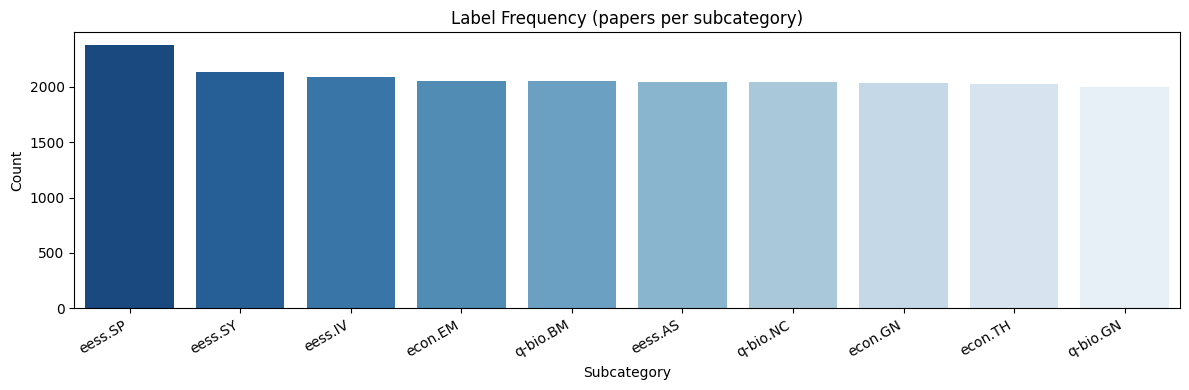

Category  Count
 eess.SP   2375
 eess.SY   2139
 eess.IV   2088
 econ.EM   2058
q-bio.BM   2050
 eess.AS   2047
q-bio.NC   2041
 econ.GN   2033
 econ.TH   2023
q-bio.GN   2001


In [5]:
# Label frequency — how often each subcategory appears
from collections import Counter

label_counts = Counter(label for labels in df['label_list'] for label in labels)
label_df     = pd.DataFrame(label_counts.items(), columns=['Category', 'Count']).sort_values('Count', ascending=False)

plt.figure(figsize=(12, 4))
sns.barplot(data=label_df, x='Category', y='Count', palette='Blues_r')
plt.title('Label Frequency (papers per subcategory)')
plt.xlabel('Subcategory')
plt.ylabel('Count')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

print(label_df.to_string(index=False))

=== Labels per document ===
n_labels
1    19126
2      813
3       33
4        1


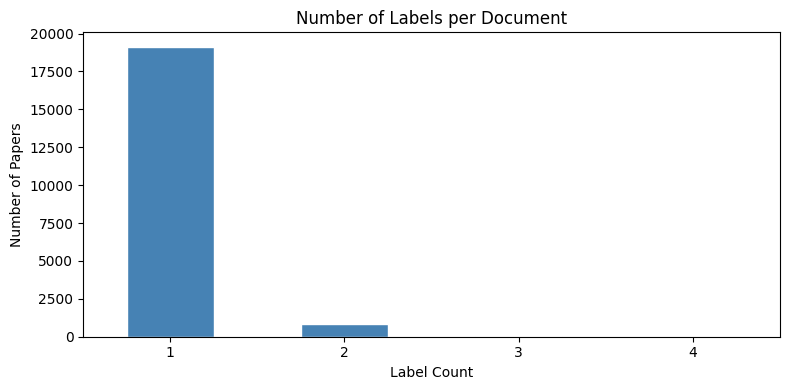

In [6]:
# Labels per document distribution — how many categories does each paper have?
df['n_labels'] = df['label_list'].apply(len)

print('=== Labels per document ===')
print(df['n_labels'].value_counts().sort_index().to_string())

plt.figure(figsize=(8, 4))
df['n_labels'].value_counts().sort_index().plot(kind='bar', color='steelblue', edgecolor='white')
plt.title('Number of Labels per Document')
plt.xlabel('Label Count')
plt.ylabel('Number of Papers')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

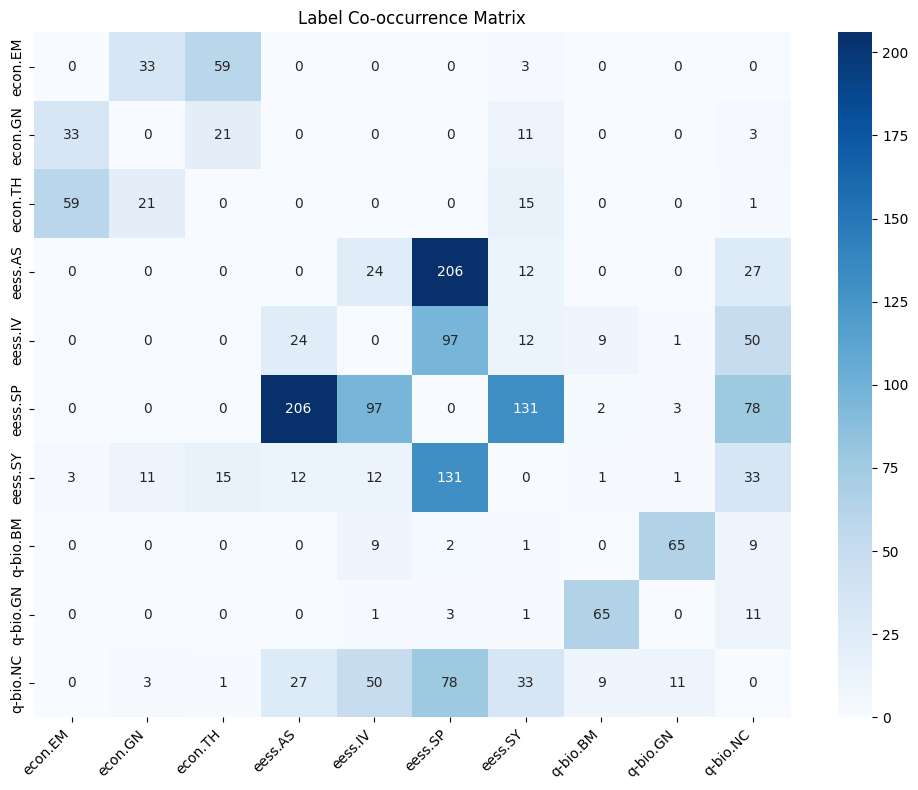

In [7]:
# Label co-occurrence heatmap
mlb_eda = MultiLabelBinarizer(classes=KNOWN_LABELS)
Y_eda   = mlb_eda.fit_transform(df['label_list'])
cooc    = (Y_eda.T @ Y_eda).astype(float)
np.fill_diagonal(cooc, 0)  # hide self-co-occurrence

plt.figure(figsize=(10, 8))
sns.heatmap(cooc, xticklabels=KNOWN_LABELS, yticklabels=KNOWN_LABELS,
            annot=True, fmt='.0f', cmap='Blues')
plt.title('Label Co-occurrence Matrix')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 5. Prepare Features & Multi-Label Target

`MultiLabelBinarizer` converts each paper's label list into a binary vector:
```
['q-bio.GN', 'q-bio.NC']  →  [0, 0, 0, 0, 0, 0, 0, 0, 1, 1]  (10-dim)
```

In [8]:
# Drop missing text
df = df.dropna(subset=['text']).reset_index(drop=True)
df = df[df['text'].str.strip() != ''].reset_index(drop=True)

X = df['text'].to_numpy(dtype=str)

# Binarise labels — fit with our fixed KNOWN_LABELS order
mlb = MultiLabelBinarizer(classes=KNOWN_LABELS)
Y   = mlb.fit_transform(df['label_list'])

print(f'X shape: {X.shape}')
print(f'Y shape: {Y.shape}  (n_papers x n_labels)')
print(f'Label columns: {list(mlb.classes_)}')
print(f'\nSample row (first paper):')
print(f'  Labels:  {df["label_list"].iloc[0]}')
print(f'  Encoded: {Y[0]}')

X shape: (19973,)
Y shape: (19973, 10)  (n_papers x n_labels)
Label columns: ['econ.EM', 'econ.GN', 'econ.TH', 'eess.AS', 'eess.IV', 'eess.SP', 'eess.SY', 'q-bio.BM', 'q-bio.GN', 'q-bio.NC']

Sample row (first paper):
  Labels:  ['q-bio.GN']
  Encoded: [0 0 0 0 0 0 0 0 1 0]


In [9]:
# Stratified multi-label split using iterative-stratification is complex;
# we use a standard split here since our label distribution is reasonably balanced
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=RANDOM_SEED
)

print(f'Train: {len(X_train):,} papers')
print(f'Test:  {len(X_test):,} papers')

Train: 15,978 papers
Test:  3,995 papers


In [10]:
# TF-IDF vectorisation — fit on train only
tfidf = TfidfVectorizer(
    max_features=20_000,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.90,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

print(f'TF-IDF train: {X_train_tfidf.shape}')
print(f'TF-IDF test:  {X_test_tfidf.shape}')

TF-IDF train: (15978, 20000)
TF-IDF test:  (3995, 20000)


## 6. Shared Evaluation Helpers

Multi-label metrics differ from single-label:

| Metric | What it measures |
|---|---|
| **Hamming Loss** | Fraction of labels wrongly predicted — lower is better |
| **F1 Micro** | Global F1 across all labels — good when label counts are unbalanced |
| **F1 Macro** | Average F1 per label — treats all labels equally regardless of frequency |
| **Jaccard Score** | Overlap between predicted and true label sets per document |

In [11]:
all_results = []   # collects summary dicts for final comparison

def evaluate_multilabel(model_name, Y_true, Y_pred):
    """Print multi-label metrics and return a summary dict."""
    hl       = hamming_loss(Y_true, Y_pred)
    f1_micro = f1_score(Y_true, Y_pred, average='micro', zero_division=0)
    f1_macro = f1_score(Y_true, Y_pred, average='macro', zero_division=0)
    jacc     = jaccard_score(Y_true, Y_pred, average='samples', zero_division=0)

    print(f'=== {model_name} ===')
    print(f'  Hamming Loss:  {hl:.4f}  (lower is better)')
    print(f'  F1 Micro:      {f1_micro:.4f}')
    print(f'  F1 Macro:      {f1_macro:.4f}')
    print(f'  Jaccard Score: {jacc:.4f}')
    print()
    print('  Per-label breakdown:')
    print(classification_report(Y_true, Y_pred, target_names=KNOWN_LABELS, zero_division=0))

    return {
        'Model': model_name,
        'Hamming Loss': hl,
        'F1 Micro': f1_micro,
        'F1 Macro': f1_macro,
        'Jaccard Score': jacc
    }


def plot_per_label_f1(Y_true, Y_pred, title):
    """Bar chart of per-label F1 scores."""
    f1_per_label = f1_score(Y_true, Y_pred, average=None, zero_division=0)
    plt.figure(figsize=(12, 4))
    bars = plt.bar(KNOWN_LABELS, f1_per_label, color='steelblue', edgecolor='white')
    for bar, val in zip(bars, f1_per_label):
        plt.text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.01,
                 f'{val:.2f}', ha='center', va='bottom', fontsize=9)
    plt.ylim(0, 1.12)
    plt.title(f'Per-Label F1 Score — {title}')
    plt.xlabel('Subcategory')
    plt.ylabel('F1 Score')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()

print('Evaluation helpers ready.')

Evaluation helpers ready.


---
## Model 1 — TF-IDF + Naive Bayes (OneVsRest)

`OneVsRestClassifier` wraps any binary classifier to handle multiple labels.  
It trains **one binary classifier per label** — e.g. "is this paper `q-bio.GN`? yes/no" — independently for all 10 labels.

In [12]:
nb = OneVsRestClassifier(MultinomialNB(alpha=0.1))
nb.fit(X_train_tfidf, Y_train)

Y_pred_nb  = nb.predict(X_test_tfidf)
results_nb = evaluate_multilabel('TF-IDF + Naive Bayes (OvR)', Y_test, Y_pred_nb)
all_results.append(results_nb)

=== TF-IDF + Naive Bayes (OvR) ===
  Hamming Loss:  0.0389  (lower is better)
  F1 Micro:      0.8214
  F1 Macro:      0.8247
  Jaccard Score: 0.7812

  Per-label breakdown:
              precision    recall  f1-score   support

     econ.EM       0.79      0.83      0.81       420
     econ.GN       0.67      0.84      0.75       427
     econ.TH       0.76      0.90      0.82       416
     eess.AS       0.88      0.93      0.90       438
     eess.IV       0.80      0.86      0.83       416
     eess.SP       0.74      0.73      0.73       483
     eess.SY       0.72      0.80      0.76       422
    q-bio.BM       0.83      0.93      0.88       380
    q-bio.GN       0.81      0.93      0.87       366
    q-bio.NC       0.94      0.86      0.90       395

   micro avg       0.79      0.86      0.82      4163
   macro avg       0.79      0.86      0.82      4163
weighted avg       0.79      0.86      0.82      4163
 samples avg       0.79      0.87      0.82      4163



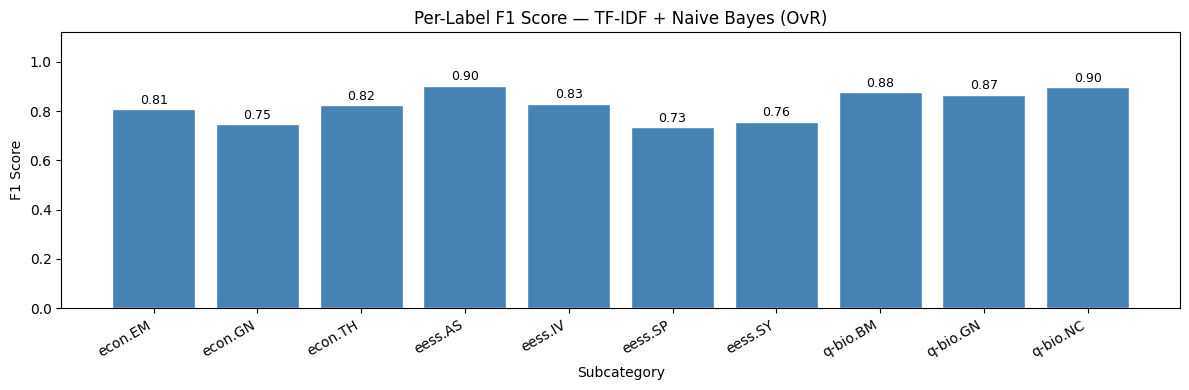

In [13]:
plot_per_label_f1(Y_test, Y_pred_nb, 'TF-IDF + Naive Bayes (OvR)')

---
## Model 2 — TF-IDF + SVM (OneVsRest)

Same OneVsRest approach but with `LinearSVC` as the binary classifier — typically stronger than Naive Bayes on TF-IDF features.

In [14]:
svm = OneVsRestClassifier(LinearSVC(max_iter=2000, C=1.0, random_state=RANDOM_SEED))
svm.fit(X_train_tfidf, Y_train)

Y_pred_svm  = svm.predict(X_test_tfidf)
results_svm = evaluate_multilabel('TF-IDF + SVM (OvR)', Y_test, Y_pred_svm)
all_results.append(results_svm)

=== TF-IDF + SVM (OvR) ===
  Hamming Loss:  0.0281  (lower is better)
  F1 Micro:      0.8567
  F1 Macro:      0.8580
  Jaccard Score: 0.8091

  Per-label breakdown:
              precision    recall  f1-score   support

     econ.EM       0.91      0.74      0.82       420
     econ.GN       0.79      0.70      0.75       427
     econ.TH       0.88      0.79      0.83       416
     eess.AS       0.98      0.93      0.95       438
     eess.IV       0.95      0.86      0.90       416
     eess.SP       0.88      0.70      0.78       483
     eess.SY       0.90      0.75      0.82       422
    q-bio.BM       0.95      0.88      0.91       380
    q-bio.GN       0.97      0.89      0.93       366
    q-bio.NC       0.93      0.86      0.90       395

   micro avg       0.91      0.81      0.86      4163
   macro avg       0.91      0.81      0.86      4163
weighted avg       0.91      0.81      0.86      4163
 samples avg       0.82      0.82      0.82      4163



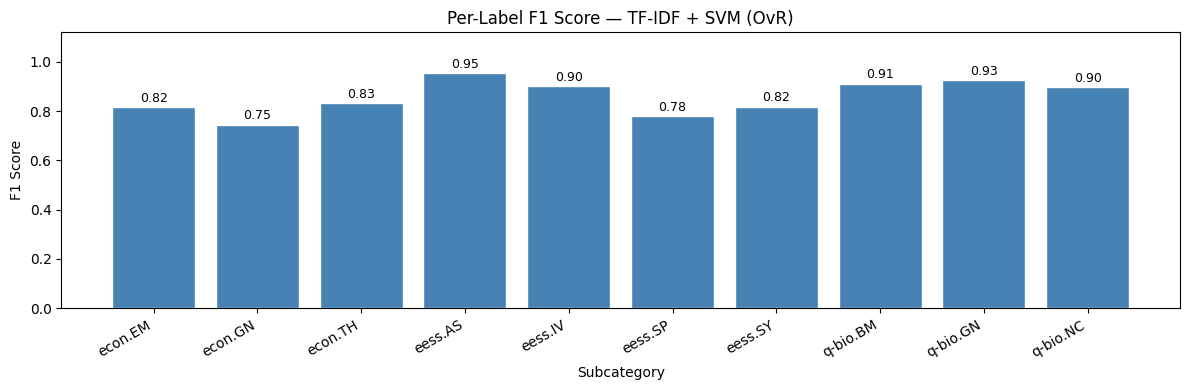

In [15]:
plot_per_label_f1(Y_test, Y_pred_svm, 'TF-IDF + SVM (OvR)')

---
## Model 3 — BERT (Fine-tuned, Multi-Label)

Key differences from single-label BERT:

| | Single-label | Multi-label |
|---|---|---|
| Output activation | `softmax` (sums to 1) | `sigmoid` (independent per label) |
| Loss function | `CrossEntropyLoss` | `BCEWithLogitsLoss` |
| Prediction | `argmax` (pick one) | threshold at 0.5 (any labels ≥ 0.5) |

> ⚠️ GPU strongly recommended. Uncomment `!pip install transformers torch` in Section 1 first.

In [16]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import BertTokenizer, BertForSequenceClassification
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')
if device.type == 'cpu':
    print('  No GPU detected — training will be slow.')
    print('  Consider running on Google Colab with GPU runtime.')

Using device: cuda


In [17]:
# BERT hyperparameters
BERT_MODEL    = 'bert-base-uncased'
MAX_LEN       = 256
BATCH_SIZE    = 16     # reduce to 8 if CUDA out-of-memory
EPOCHS        = 3
LEARNING_RATE = 2e-5
THRESHOLD     = 0.1    # sigmoid probability above this = label predicted as active
NUM_LABELS    = len(KNOWN_LABELS)

print(f'Labels: {NUM_LABELS} | MAX_LEN={MAX_LEN} | BATCH_SIZE={BATCH_SIZE} | THRESHOLD={THRESHOLD}')

Labels: 10 | MAX_LEN=256 | BATCH_SIZE=16 | THRESHOLD=0.1


In [18]:
# Tokenise
tokenizer = BertTokenizer.from_pretrained(BERT_MODEL)

train_encodings = tokenizer(
    list(X_train), max_length=MAX_LEN,
    padding='max_length', truncation=True, return_tensors='pt'
)
test_encodings = tokenizer(
    list(X_test), max_length=MAX_LEN,
    padding='max_length', truncation=True, return_tensors='pt'
)

print(f'Train encodings: {train_encodings["input_ids"].shape}')
print(f'Test  encodings: {test_encodings["input_ids"].shape}')

Train encodings: torch.Size([15978, 256])
Test  encodings: torch.Size([3995, 256])


In [19]:
# Multi-label Dataset — labels are float tensors for BCEWithLogitsLoss
class ArxivMultiLabelDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        # float32 required for BCEWithLogitsLoss (vs long for CrossEntropyLoss)
        self.labels = torch.tensor(labels, dtype=torch.float32)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = self.labels[idx]
        return item

train_dataset = ArxivMultiLabelDataset(train_encodings, Y_train)
test_dataset  = ArxivMultiLabelDataset(test_encodings,  Y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE)

print(f'Train batches: {len(train_loader)} | Test batches: {len(test_loader)}')

Train batches: 999 | Test batches: 250


In [20]:
# Load BERT — problem_type='multi_label_classification' sets sigmoid + BCEWithLogitsLoss automatically
bert_model = BertForSequenceClassification.from_pretrained(
    BERT_MODEL,
    num_labels=NUM_LABELS,
    problem_type='multi_label_classification'  # <-- key difference from single-label
)
bert_model.to(device)

optimizer   = AdamW(bert_model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
total_steps = len(train_loader) * EPOCHS
scheduler   = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)

print(f'BERT loaded for multi-label. Total training steps: {total_steps}')

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 937.93it/s, Materializing param=bert.pooler.dense.weight]                               
BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those pa

BERT loaded for multi-label. Total training steps: 2997


In [21]:
# Fine-tuning loop
train_losses = []

for epoch in range(EPOCHS):
    bert_model.train()
    total_loss = 0

    for batch_num, batch in enumerate(train_loader):
        optimizer.zero_grad()

        outputs = bert_model(
            input_ids      = batch['input_ids'].to(device),
            attention_mask = batch['attention_mask'].to(device),
            labels         = batch['labels'].to(device)   # float32 binary vectors
        )

        loss = outputs.loss   # BCEWithLogitsLoss (sigmoid applied internally)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(bert_model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        total_loss += loss.item()

        if (batch_num + 1) % 20 == 0:
            print(f'  Epoch {epoch+1}/{EPOCHS} | Batch {batch_num+1}/{len(train_loader)} | Loss: {loss.item():.4f}')

    avg_loss = total_loss / len(train_loader)
    train_losses.append(avg_loss)
    print(f'Epoch {epoch+1}/{EPOCHS} complete — Avg Loss: {avg_loss:.4f}\n')

  Epoch 1/3 | Batch 20/999 | Loss: 0.7225
  Epoch 1/3 | Batch 40/999 | Loss: 0.6679
  Epoch 1/3 | Batch 60/999 | Loss: 0.5731
  Epoch 1/3 | Batch 80/999 | Loss: 0.4829
  Epoch 1/3 | Batch 100/999 | Loss: 0.4173
  Epoch 1/3 | Batch 120/999 | Loss: 0.3814
  Epoch 1/3 | Batch 140/999 | Loss: 0.3556
  Epoch 1/3 | Batch 160/999 | Loss: 0.3418
  Epoch 1/3 | Batch 180/999 | Loss: 0.3250
  Epoch 1/3 | Batch 200/999 | Loss: 0.2973
  Epoch 1/3 | Batch 220/999 | Loss: 0.2889
  Epoch 1/3 | Batch 240/999 | Loss: 0.2713
  Epoch 1/3 | Batch 260/999 | Loss: 0.2281
  Epoch 1/3 | Batch 280/999 | Loss: 0.2258
  Epoch 1/3 | Batch 300/999 | Loss: 0.2287
  Epoch 1/3 | Batch 320/999 | Loss: 0.2051
  Epoch 1/3 | Batch 340/999 | Loss: 0.1685
  Epoch 1/3 | Batch 360/999 | Loss: 0.1762
  Epoch 1/3 | Batch 380/999 | Loss: 0.1522
  Epoch 1/3 | Batch 400/999 | Loss: 0.1700
  Epoch 1/3 | Batch 420/999 | Loss: 0.1565
  Epoch 1/3 | Batch 440/999 | Loss: 0.1461
  Epoch 1/3 | Batch 460/999 | Loss: 0.1472
  Epoch 1/3 | B

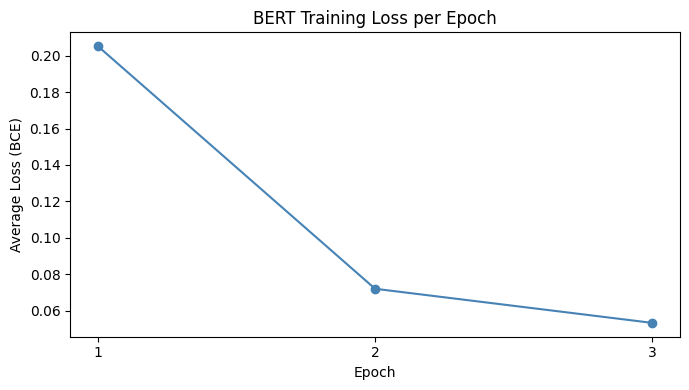

In [22]:
# Training loss curve
plt.figure(figsize=(7, 4))
plt.plot(range(1, EPOCHS + 1), train_losses, marker='o', color='steelblue')
plt.title('BERT Training Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Average Loss (BCE)')
plt.xticks(range(1, EPOCHS + 1))
plt.tight_layout()
plt.show()

In [23]:
# Evaluate BERT — sigmoid outputs thresholded at 0.5
bert_model.eval()
all_probs = []

with torch.no_grad():
    for batch in test_loader:
        outputs = bert_model(
            input_ids      = batch['input_ids'].to(device),
            attention_mask = batch['attention_mask'].to(device)
        )
        probs = torch.sigmoid(outputs.logits).cpu().numpy()
        all_probs.append(probs)

all_probs  = np.vstack(all_probs)
Y_pred_bert = (all_probs >= THRESHOLD).astype(int)

results_bert = evaluate_multilabel('BERT (fine-tuned, multi-label)', Y_test, Y_pred_bert)
all_results.append(results_bert)

=== BERT (fine-tuned, multi-label) ===
  Hamming Loss:  0.0318  (lower is better)
  F1 Micro:      0.8596
  F1 Macro:      0.8662
  Jaccard Score: 0.8512

  Per-label breakdown:
              precision    recall  f1-score   support

     econ.EM       0.75      0.92      0.83       420
     econ.GN       0.66      0.92      0.77       427
     econ.TH       0.80      0.94      0.86       416
     eess.AS       0.94      0.98      0.96       438
     eess.IV       0.84      0.95      0.89       416
     eess.SP       0.65      0.88      0.75       483
     eess.SY       0.79      0.89      0.83       422
    q-bio.BM       0.87      0.96      0.91       380
    q-bio.GN       0.90      0.96      0.93       366
    q-bio.NC       0.88      0.97      0.93       395

   micro avg       0.80      0.94      0.86      4163
   macro avg       0.81      0.94      0.87      4163
weighted avg       0.80      0.94      0.86      4163
 samples avg       0.86      0.95      0.89      4163



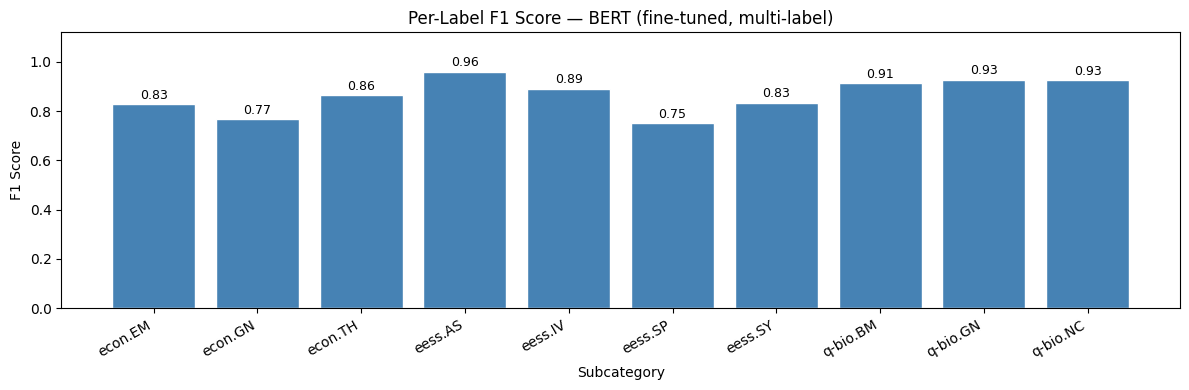

In [24]:
plot_per_label_f1(Y_test, Y_pred_bert, 'BERT (fine-tuned, multi-label)')

In [25]:
# Save BERT model
os.makedirs('models/bert_multilabel', exist_ok=True)
bert_model.save_pretrained('models/bert_multilabel')
tokenizer.save_pretrained('models/bert_multilabel')
print('BERT multi-label model saved to models/bert_multilabel/')

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.88it/s]

BERT multi-label model saved to models/bert_multilabel/


---
## 8. Model Comparison

In [26]:
results_df = pd.DataFrame(all_results).set_index('Model').round(4)
print('=== Final Model Comparison ===')
print(results_df.to_string())

=== Final Model Comparison ===
                                Hamming Loss  F1 Micro  F1 Macro  Jaccard Score
Model                                                                          
TF-IDF + Naive Bayes (OvR)            0.0389    0.8214    0.8247         0.7812
TF-IDF + SVM (OvR)                    0.0281    0.8567    0.8580         0.8091
BERT (fine-tuned, multi-label)        0.0318    0.8596    0.8662         0.8512


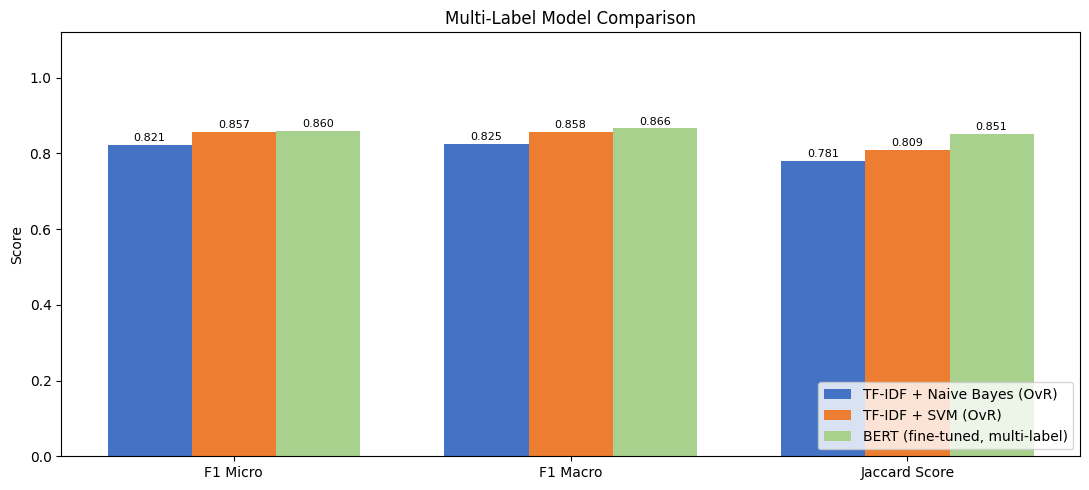

Hamming Loss (lower is better):
                                Hamming Loss
Model                                       
TF-IDF + Naive Bayes (OvR)            0.0389
TF-IDF + SVM (OvR)                    0.0281
BERT (fine-tuned, multi-label)        0.0318


In [27]:
# Grouped bar chart — note: Hamming Loss is inverted (lower = better)
metrics_plot = ['F1 Micro', 'F1 Macro', 'Jaccard Score']
x      = np.arange(len(metrics_plot))
width  = 0.25
colors = ['#4472C4', '#ED7D31', '#A9D18E']

fig, ax = plt.subplots(figsize=(11, 5))
for i, (model_name, row) in enumerate(results_df.iterrows()):
    bars = ax.bar(x + i * width, [row[m] for m in metrics_plot], width, label=model_name, color=colors[i])
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.005,
            f'{bar.get_height():.3f}',
            ha='center', va='bottom', fontsize=8
        )

ax.set_xticks(x + width)
ax.set_xticklabels(metrics_plot)
ax.set_ylim(0, 1.12)
ax.set_ylabel('Score')
ax.set_title('Multi-Label Model Comparison')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

# Also print Hamming Loss separately (lower = better)
print('Hamming Loss (lower is better):')
print(results_df[['Hamming Loss']].to_string())

In [28]:
best_model_name = results_df['F1 Micro'].idxmax()
print(f'Best model by F1 Micro: {best_model_name}')
print(f'  F1 Micro:      {results_df.loc[best_model_name, "F1 Micro"]:.4f}')
print(f'  F1 Macro:      {results_df.loc[best_model_name, "F1 Macro"]:.4f}')
print(f'  Jaccard Score: {results_df.loc[best_model_name, "Jaccard Score"]:.4f}')
print(f'  Hamming Loss:  {results_df.loc[best_model_name, "Hamming Loss"]:.4f}')

Best model by F1 Micro: BERT (fine-tuned, multi-label)
  F1 Micro:      0.8596
  F1 Macro:      0.8662
  Jaccard Score: 0.8512
  Hamming Loss:  0.0318


---
## 9. Predict All Categories for a New Paper

Paste any title + abstract to get **all predicted subcategories** from each model.

In [29]:
def predict_tfidf_multilabel(title, abstract, model, vectoriser=None):
    """
    Predict multiple categories using a TF-IDF OvR model.
    Returns a list of predicted subcategory strings.
    """
    if vectoriser is None:
        vectoriser = tfidf
    text      = (title.strip() + ' ' + abstract.strip()).lower()
    features  = vectoriser.transform([text])
    pred_vec  = model.predict(features)[0]              # binary vector length 10
    predicted = [KNOWN_LABELS[i] for i, v in enumerate(pred_vec) if v == 1]
    return predicted if predicted else ['(no label predicted)']


def predict_bert_multilabel(title, abstract, threshold=THRESHOLD):
    """
    Predict multiple categories using fine-tuned BERT.
    Returns predicted labels and their sigmoid confidence scores.
    """
    text   = title.strip() + ' ' + abstract.strip()
    inputs = tokenizer(
        text, return_tensors='pt',
        max_length=MAX_LEN, truncation=True, padding='max_length'
    )
    bert_model.eval()
    with torch.no_grad():
        outputs = bert_model(
            input_ids      = inputs['input_ids'].to(device),
            attention_mask = inputs['attention_mask'].to(device)
        )
    probs     = torch.sigmoid(outputs.logits).cpu().numpy()[0]
    predicted = [(KNOWN_LABELS[i], round(float(p), 4))
                 for i, p in enumerate(probs) if p >= threshold]
    all_scores = {KNOWN_LABELS[i]: round(float(p), 4) for i, p in enumerate(probs)}
    return predicted if predicted else [('(no label predicted)', 0.0)], all_scores

print('Prediction functions ready.')

Prediction functions ready.


In [30]:
# Example — a genomics paper that also touches signal processing
sample_title = "Bayesian inference of gene regulatory networks from single-cell RNA sequencing data"
sample_abstract = """
We present a probabilistic graphical model for reconstructing gene regulatory networks
from single-cell RNA sequencing data. Our approach uses variational inference to
estimate posterior distributions over network edges, accounting for measurement noise
and dropout events common in scRNA-seq experiments. We validate on both simulated
genomic data and real biological datasets.
"""

print(f'Title: "{sample_title}"\n')

nb_pred   = predict_tfidf_multilabel(sample_title, sample_abstract, nb)
svm_pred  = predict_tfidf_multilabel(sample_title, sample_abstract, svm)
bert_pred, bert_scores = predict_bert_multilabel(sample_title, sample_abstract)

print(f'Naive Bayes predicted categories: {nb_pred}')
print(f'SVM         predicted categories: {svm_pred}')
print(f'BERT        predicted categories: {[(label, score) for label, score in bert_pred]}')
print(f'\nBERT all label scores:')
for label, score in sorted(bert_scores.items(), key=lambda x: -x[1]):
    bar = '█' * int(score * 30)
    marker = ' ← predicted' if score >= THRESHOLD else ''
    print(f'  {label:12s}  {score:.4f}  {bar}{marker}')

Title: "Bayesian inference of gene regulatory networks from single-cell RNA sequencing data"

Naive Bayes predicted categories: ['q-bio.GN']
SVM         predicted categories: ['q-bio.GN']
BERT        predicted categories: [('q-bio.GN', 0.9724)]

BERT all label scores:
  q-bio.GN      0.9724  █████████████████████████████ ← predicted
  q-bio.BM      0.0144  
  econ.EM       0.0121  
  econ.TH       0.0106  
  eess.SY       0.0100  
  econ.GN       0.0098  
  q-bio.NC      0.0091  
  eess.SP       0.0084  
  eess.IV       0.0083  
  eess.AS       0.0075  


In [31]:
# Try your own paper
my_title    = "HMS-VesselNet: Hierarchical Multi-Scale Attention Network with Topology-Preserving Loss for Retinal Vessel Segmentation"   # <-- paste your title here
my_abstract = "Retinal vessel segmentation methods based on standard overlap losses tend to miss thin peripheral vessels because these structures occupy very few pixels and have low contrast against the background. To address this, we propose HMS-VesselNet, a hierarchical multi-scale network that processes fundus images across four parallel branches at different resolutions and combines their outputs using learned fusion weights. The training loss combines Dice, binary cross-entropy, and centerline Dice to jointly optimize area overlap and vessel continuity. Hard example mining is applied from epoch 20 onward to concentrate gradient updates on the most difficult training images. Tested on 68 images from DRIVE, STARE, and CHASE_DB1 using 5-fold cross-validation, the model achieves a mean Dice of 88.72±0.67%, Sensitivity of 90.78±1.42%, and AUC of 98.25±0.21%. In leave-one-dataset-out experiments, AUC remains above 95% on each unseen dataset. The largest improvement is in the recall of thin peripheral vessels, which are the structures most frequently missed by standard methods and most critical for early detection of diabetic retinopathy."   # <-- paste your abstract here

if my_title and my_abstract:
    print(f'Title: "{my_title}"\n')
    nb_pred  = predict_tfidf_multilabel(my_title, my_abstract, nb)
    svm_pred = predict_tfidf_multilabel(my_title, my_abstract, svm)
    bert_pred, bert_scores = predict_bert_multilabel(my_title, my_abstract)

    print(f'Naive Bayes: {nb_pred}')
    print(f'SVM:         {svm_pred}')
    print(f'BERT:        {[(label, score) for label, score in bert_pred]}')
    print(f'\nBERT all label scores:')
    for label, score in sorted(bert_scores.items(), key=lambda x: -x[1]):
        bar    = '█' * int(score * 30)
        marker = ' ← predicted' if score >= THRESHOLD else ''
        print(f'  {label:12s}  {score:.4f}  {bar}{marker}')
else:
    print('Fill in my_title and my_abstract above to classify your own paper.')

Title: "HMS-VesselNet: Hierarchical Multi-Scale Attention Network with Topology-Preserving Loss for Retinal Vessel Segmentation"

Naive Bayes: ['eess.IV']
SVM:         ['eess.IV']
BERT:        [('eess.IV', 0.9667)]

BERT all label scores:
  eess.IV       0.9667  █████████████████████████████ ← predicted
  eess.SP       0.0174  
  q-bio.NC      0.0145  
  econ.EM       0.0101  
  econ.TH       0.0095  
  eess.AS       0.0091  
  eess.SY       0.0091  
  econ.GN       0.0085  
  q-bio.BM      0.0084  
  q-bio.GN      0.0079  


In [33]:
# Try your own paper
my_title    = "Genome wide identification of regulatory networks associated with general cognitive ability using a normalized alignment free similarity measure of promoter regions"   # <-- paste your title here
my_abstract = "We show that a normalized alignment free similarity measure, called D2z, can be used to detect potential regulatory relations for gene sets when little is known about the regulatory elements involved. One scenario where such gene sets arise is genome wide association studies (GWAS). In this work we consider a gene set from a GWAS on childhood general cognitive ability. We build a co-regulation network for the GWAS genes based on the D2z scores, which shows potential co-regulatory relationships between the genes as well as predict additional genes that are likely to be part of the network. We found that the set of the predicted genes is enriched in genes associated with mental retardation and GO terms such as synapse and neuron development. In particular, we found strong evidence of regulatory connection between the GWAS genes and CHL1, a gene known to be involved in mental retardation."   # <-- paste your abstract here
THRESHOLD = 0.04
if my_title and my_abstract:
    print(f'Title: "{my_title}"\n')
    nb_pred  = predict_tfidf_multilabel(my_title, my_abstract, nb)
    svm_pred = predict_tfidf_multilabel(my_title, my_abstract, svm)
    bert_pred, bert_scores = predict_bert_multilabel(my_title, my_abstract)

    print(f'Naive Bayes: {nb_pred}')
    print(f'SVM:         {svm_pred}')
    print(f'BERT:        {[(label, score) for label, score in bert_pred]}')
    print(f'\nBERT all label scores:')
    for label, score in sorted(bert_scores.items(), key=lambda x: -x[1]):
        bar    = '█' * int(score * 30)
        marker = ' ← predicted' if score >= THRESHOLD else ''
        print(f'  {label:12s}  {score:.4f}  {bar}{marker}')
else:
    print('Fill in my_title and my_abstract above to classify your own paper.')

Title: "Genome wide identification of regulatory networks associated with general cognitive ability using a normalized alignment free similarity measure of promoter regions"

Naive Bayes: ['q-bio.GN']
SVM:         ['q-bio.GN']
BERT:        [('q-bio.GN', 0.9587)]

BERT all label scores:
  q-bio.GN      0.9587  ████████████████████████████ ← predicted
  q-bio.NC      0.0450  █ ← predicted
  q-bio.BM      0.0153  
  econ.GN       0.0094  
  eess.AS       0.0092  
  econ.EM       0.0091  
  eess.SP       0.0091  
  econ.TH       0.0083  
  eess.SY       0.0080  
  eess.IV       0.0060  
